In [1]:
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import geoutils as gu
import numpy as np

In [2]:
glacier = "Kask"
variable = "v"
feature = "phase"

if glacier == "Russel":
    path_save = f"/Users/charriel/Documents/Seasonality/Russel/"
    tiff_path = (
        f"/Users/charriel/Documents/Seasonality/Russel/ITS_LIVE/{feature}{variable}.tif"
    )
    aspect_angle_mask = f"/Users/charriel/Documents/Seasonality/Russel/similar_aspect_and_slope.tif"
    slope_path = "/Users/charriel/Documents/Seasonality/Russel/arcticdem_v4.1_32m_slope.tif"
    aspect_path = "/Users/charriel/Documents/Seasonality/Russel/arcticdem_v4.1_32m_aspect.tif"

elif glacier == "Kask":
    path_save = f"/Users/charriel/Documents/Seasonality/Yukon/"
    tiff_path = (
        f"/Users/charriel/Documents/Seasonality/Yukon/ITS_LIVE/{feature}{variable}.tif"
    )
    aspect_angle_mask = f"/Users/charriel/Documents/Seasonality/Yukon/similar_aspect_and_slope.tif"
    slope_path = "/Users/charriel/Documents/Seasonality/Yukon/DEM/viz (1)/Yukon_slope.tif"
    aspect_path = "/Users/charriel/Documents/Seasonality/Yukon/DEM/viz (1)/Yukon_aspect.tif"


In [3]:
# Load rasters
amplitude = gu.Raster(tiff_path)
slope = gu.Raster(slope_path)
aspect = gu.Raster(aspect_path)

mask_amplitude_aspect = gu.Raster(aspect_angle_mask)

# Ensure they are aligned
# Reproject / resample mask to match raster_A grid if needed
mask_amplitude_aspect_reproject = mask_amplitude_aspect.reproject(amplitude)
mask_slope_aspect_reproject = mask_amplitude_aspect.reproject(slope)

# Get pixel values outside where the mask is equal to 1
pixel_values = amplitude.data.data[(mask_amplitude_aspect_reproject.data.data == 1) & (amplitude.data.data != -9.9999e+04)]
slope_values = slope.data.data[(mask_slope_aspect_reproject.data.data == 1)]
aspect_values = aspect.data.data[(mask_slope_aspect_reproject.data.data == 1)]

if pixel_values.size == 0:
    raise ValueError("No valid pixel values found after removing NaNs.")


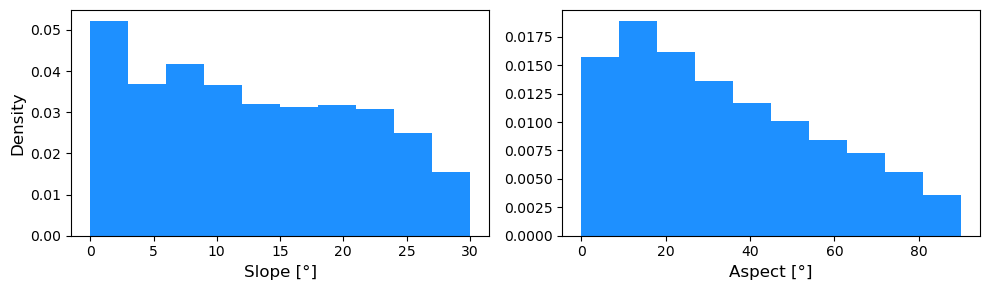

In [4]:
fig, ax = plt.subplots(1,2,figsize=(10, 3))

# Histogram
ax[0].hist(
    slope_values,
    bins=10,
    density=True,
    color="dodgerblue",
)
ax[1].hist(
    aspect_values,
    bins=10,
    density=True,
    color="dodgerblue",
)
ax[0].set_xlabel(f"Slope [°]",fontsize=12)
ax[1].set_xlabel(f"Aspect [°]",fontsize=12)
ax[0].set_ylabel("Density",fontsize=12)
plt.tight_layout()
plt.show()
fig.savefig(f"{path_save}/slope_and_aspect_distribution.png")


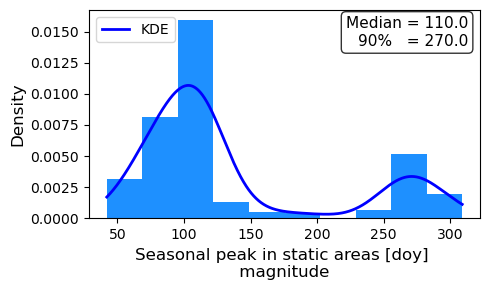

In [5]:
# -------------------------
# Statistics
# -------------------------
median = np.median(pixel_values)
mean = np.mean(pixel_values)
std = np.std(pixel_values)
p90 = np.percentile(pixel_values, 90, axis=0)

# NMAD = 1.4826 * median(|x - median(x)|)
nmad = 1.4826 * np.median(np.abs(pixel_values - median))

# -------------------------
# Plot
# -------------------------
fig, ax = plt.subplots(figsize=(5, 3))

# Histogram
ax.hist(
    pixel_values,
    bins=10,
    density=True,
    color="dodgerblue",
)

# KDE
kde = gaussian_kde(pixel_values)
x_vals = np.linspace(pixel_values.min(), pixel_values.max(), 1000)
ax.plot(x_vals, kde(x_vals), "b-", linewidth=2, label="KDE")

# Labels
if feature == "phase":label_feature="peak"
else: label_feature="amplitude"
if feature == "phase":unit = "[doy]"
else: unit = "[m/y]"
if variable == "v":
    ax.set_xlabel(f"Seasonal {label_feature} in static areas {unit} \n magnitude ",fontsize=12)
else:
    ax.set_xlabel(f"Seasonal {label_feature} in static areas {unit} \n {variable}-component ",fontsize=12)
ax.set_ylabel("Density",fontsize=12)
ax.legend()

# -------------------------
# Text box with statistics
# -------------------------
stats_text = (
    f"Median = {median:.1f}\n"
    f"90%   = {p90:.1f}"
)

ax.text(
    0.97, 0.97,
    stats_text,
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top",
    horizontalalignment="right",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
)

plt.tight_layout()
plt.show()
fig.savefig(f"{path_save}/stats_sinusoidal_fit_in_static_areas_{feature}_{variable}.png")
